# Kalman filters
From the book *Bayesian Methods for Autonomous Robotics and Intelligent Infrastructure Systems* by Khalid M. Mosalam.

Companion to **Kalman Filter: Bayesian Estimation Over Time**, **Extended Kalman Filter (EKF)**, and **Unscented Kalman Filter (UKF)**.

All numerical examples use synthetic or illustrative data.

Run top to bottom. Dependencies: NumPy and Matplotlib.

Figure styling: Ziad Mosalam. Run all cells from this notebook directory. Each figure is displayed below its calculation and exported to `../figures/` as PDF and PNG. The original simulation and estimation calculations are unchanged.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib.ticker import MultipleLocator

plt.style.use('book.mplstyle')
Path('../figures').mkdir(exist_ok=True)

BLUE = '#003262'
GOLD = '#B17A00'
TEAL = '#247C86'
INK = '#30363B'
GRAY = '#7D858B' 

np.random.seed(42)

### 1D Motion Estimation

In [2]:
x, P = 0, 1
Q, R = 0.2, 0.5
z = [1.2, 2.0]
for zi in z:
    x_pred = x + 1
    P_pred = P + Q
    K = P_pred / (P_pred + R)
    x = x_pred + K * (zi - x_pred)
    P = (1 - K) * P_pred
    print(f"Estimate: {x:.3f}, Uncertainty: {P:.3f}")

Estimate: 1.141, Uncertainty: 0.353
Estimate: 2.067, Uncertainty: 0.263


### Extended Kalman Filter (EKF) Example (1D nonlinear system)

In [3]:
def ekf_predict(x, P, u, Q, f, Fx):
    x_pred = f(x, u)
    F = Fx(x, u)
    P_pred = F @ P @ F.T + Q
    return x_pred, P_pred

def ekf_update(x_pred, P_pred, z, R, h, Hx):
    z_pred = h(x_pred)
    H = Hx(x_pred)
    y = z - z_pred
    S = H @ P_pred @ H.T + R
    K = P_pred @ H.T @ np.linalg.inv(S)
    x_upd = x_pred + K @ y
    P_upd = (np.eye(len(x_pred)) - K @ H) @ P_pred
    return x_upd, P_upd

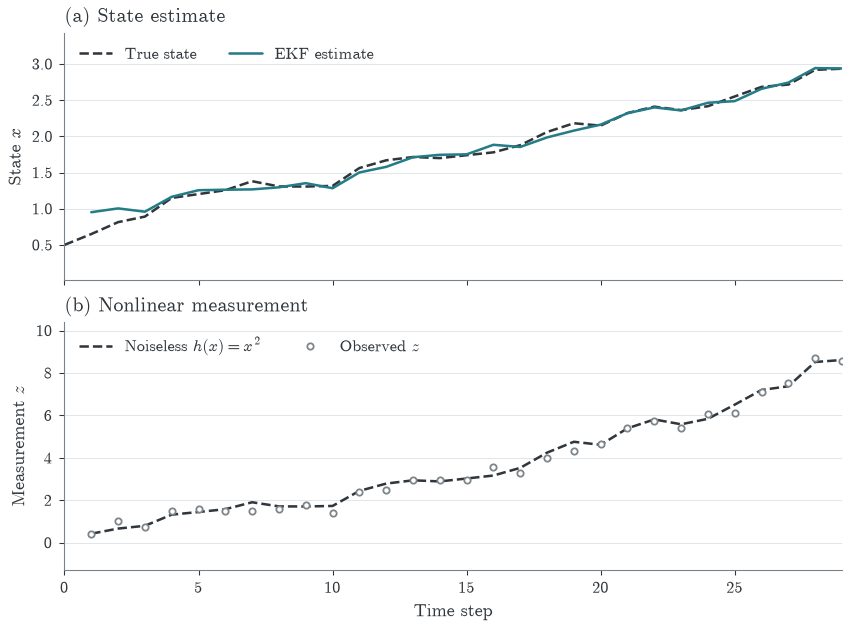

In [4]:
############ System setup ############
# State transition: x_{k+1} = x + u
f = lambda x, u: x + u
Fx = lambda x, u: np.array([[1]])  # Jacobian of f wrt x

# Measurement: z = x^2
h = lambda x: np.array([x[0] ** 2])
Hx = lambda x: np.array([[2 * x[0]]])  # Jacobian of h wrt x

############ Simulation setup ############
np.random.seed(42)
n_steps = 30
x_true = np.zeros(n_steps)
z_obs = np.zeros(n_steps)

x_true[0] = 0.5
u = np.array([0.1])
Q = np.array([[0.01]])
R = np.array([[0.05]])

for k in range(1, n_steps):
    x_true[k] = f(np.array([x_true[k-1]]), u)[0] + np.random.normal(0, np.sqrt(Q[0,0]))
    z_obs[k] = h(np.array([x_true[k]]))[0] + np.random.normal(0, np.sqrt(R[0,0]))

############ EKF initialization ############
x_est = np.array([0.0])
P = np.array([[1.0]])
x_estimates = []

for k in range(1, n_steps):
    # Predict
    x_pred, P_pred = ekf_predict(x_est, P, u, Q, f, Fx)
    # Update
    x_est, P = ekf_update(x_pred, P_pred, np.array([z_obs[k]]), R, h, Hx)
    x_estimates.append(x_est[0])

############ Visualization ############
# The sensor measures x squared, so state and measurement need separate axes.
fig, axes = plt.subplots(2, 1, figsize=(6.5, 4.8), sharex=True,
                         layout='constrained')
axes[0].plot(range(n_steps), x_true, color=INK, linestyle='--', label='True state')
axes[0].plot(range(1, n_steps), x_estimates, color=TEAL, label='EKF estimate')
axes[0].set_ylabel('State $x$')
axes[0].set_title('(a) State estimate', loc='left')
axes[0].legend(ncol=2, loc='upper left')
axes[0].margins(y=0.20)

axes[1].plot(range(1, n_steps), x_true[1:]**2, color=INK,
             linestyle='--', label='Noiseless $h(x)=x^2$')
axes[1].plot(range(1, n_steps), z_obs[1:], linestyle='none', marker='o',
             markersize=3.5, markerfacecolor='white', markeredgecolor=GRAY,
             label='Observed $z$')
axes[1].set_title('(b) Nonlinear measurement', loc='left')
axes[1].set(xlabel='Time step', ylabel='Measurement $z$', xlim=(0, n_steps-1))
axes[1].legend(ncol=2, loc='upper left')
axes[1].margins(y=0.20)
axes[1].xaxis.set_major_locator(MultipleLocator(5))
for ax in axes:
    ax.grid(axis='y')
fig.savefig('../figures/kalman-ekf-state-measurement.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig('../figures/kalman-ekf-state-measurement.png', dpi=200)
plt.show()

### Unscented Kalman Filter (UKF) Example (1D nonlinear system)

In [5]:
def unscented_transform(X, Wm, Wc):
    # X: sigma points; Wm: mean of weight; Wc: cov of weights
    xm = np.sum(Wm[:, None] * X, axis=0)
    Xc = X - xm
    P  = Xc.T @ (Wc[:, None] * Xc)
    return xm, P

def sigma_points_and_weights(x, P, alpha=1e-3, beta=2.0, kappa=0.0):
    n = x.size
    lam = alpha**2 * (n + kappa) - n
    c = n + lam
    S = np.linalg.cholesky(c * P)
    X = np.zeros((2*n + 1, n))
    X[0] = x
    for i in range(n):
        X[i+1]     = x + S[:, i]
        X[i+1+n]   = x - S[:, i]
    Wm = np.full(2*n+1, 1/(2*c)); Wm[0] = lam/c
    Wc = np.full(2*n+1, 1/(2*c)); Wc[0] = lam/c + (1 - alpha**2 + beta)
    return X, Wm, Wc

In [6]:
############ UKF: predict / update (similar to EKF) ############
def ukf_predict(x, P, u, Q, alpha=1e-3, beta=2.0, kappa=0.0):
    X, Wm, Wc = sigma_points_and_weights(x, P, alpha, beta, kappa)
    X_pred = np.array([f(xi, u) for xi in X])
    x_pred, P_pred = unscented_transform(X_pred, Wm, Wc)
    P_pred = P_pred + Q
    # Regenerate from the predicted covariance so measurement statistics include Q.
    X_pred, Wm, Wc = sigma_points_and_weights(x_pred, P_pred, alpha, beta, kappa)
    return x_pred, P_pred, X_pred, Wm, Wc

def ukf_update(x_pred, P_pred, z, R, X_pred, Wm, Wc):
    Z = np.array([h(xi) for xi in X_pred])           # (2n+1, m), m=1
    z_pred, S = unscented_transform(Z, Wm, Wc)
    S = S + R
    # cross-covariance Pxz = sum Wc * (Xi-x)(Zi-z)^T
    Xc = X_pred - x_pred
    Zc = Z - z_pred
    Pxz = np.sum(Wc[:,None,None] * Xc[:,:,None] * Zc[:,None,:], axis=0)  # (n,m)
    K = Pxz @ np.linalg.inv(S)
    x_upd = x_pred + (K @ (z - z_pred)).reshape(-1)
    P_upd = P_pred - K @ S @ K.T
    return x_upd, P_upd

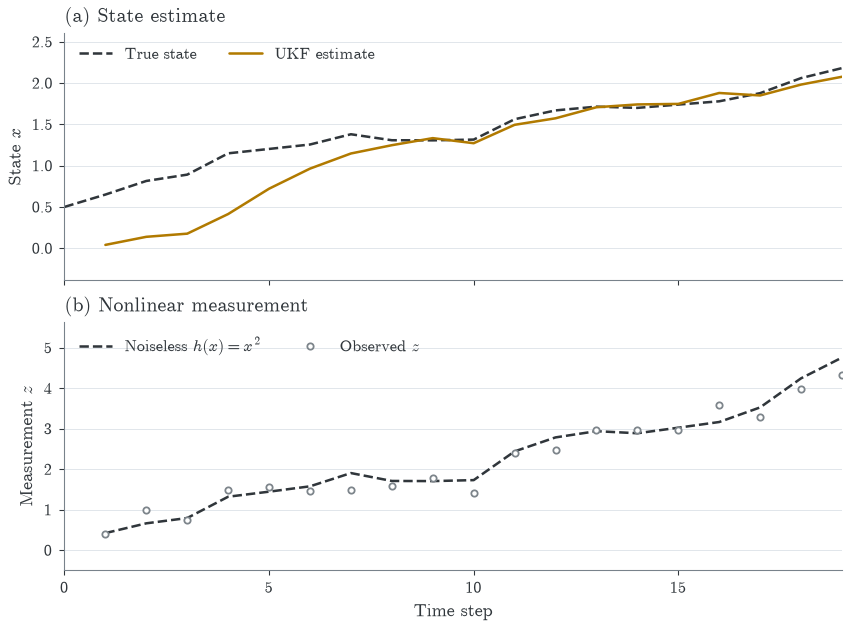

In [7]:
############ System Setup (same spirit as EKF demo) ############
# x_{k+1} = x_k + u + w
f = lambda x, u: x + u
# z_k = x_k^2 + v
h = lambda x: np.array([x[0]**2])

############ Simulation setup ############
np.random.seed(42)
n_steps = 20
x_true = np.zeros(n_steps); z_obs = np.zeros(n_steps)
x_true[0] = 0.5
u = np.array([0.1]); Q = np.array([[0.01]]); R = np.array([[0.05]])

for k in range(1, n_steps):
    x_true[k] = f(np.array([x_true[k-1]]), u)[0] + np.random.normal(0, np.sqrt(Q[0,0]))
    z_obs[k]  = h(np.array([x_true[k]]))[0]     + np.random.normal(0, np.sqrt(R[0,0]))

############ UKF initialization ############
x = np.array([0.0]); P = np.array([[1.0]])
est = []
for k in range(1, n_steps):
    x_pred, P_pred, X_pred, Wm, Wc = ukf_predict(x, P, u, Q)
    x, P = ukf_update(x_pred, P_pred, np.array([z_obs[k]]), R, X_pred, Wm, Wc)
    est.append(x[0])

############ Visualization ############
# The sensor measures x squared, so state and measurement need separate axes.
fig, axes = plt.subplots(2, 1, figsize=(6.5, 4.8), sharex=True,
                         layout='constrained')
axes[0].plot(range(n_steps), x_true, color=INK, linestyle='--', label='True state')
axes[0].plot(range(1, n_steps), est, color=GOLD, label='UKF estimate')
axes[0].set_ylabel('State $x$')
axes[0].set_title('(a) State estimate', loc='left')
axes[0].legend(ncol=2, loc='upper left')
axes[0].margins(y=0.20)

axes[1].plot(range(1, n_steps), x_true[1:]**2, color=INK,
             linestyle='--', label='Noiseless $h(x)=x^2$')
axes[1].plot(range(1, n_steps), z_obs[1:], linestyle='none', marker='o',
             markersize=3.5, markerfacecolor='white', markeredgecolor=GRAY,
             label='Observed $z$')
axes[1].set_title('(b) Nonlinear measurement', loc='left')
axes[1].set(xlabel='Time step', ylabel='Measurement $z$', xlim=(0, n_steps-1))
axes[1].legend(ncol=2, loc='upper left')
axes[1].margins(y=0.20)
axes[1].xaxis.set_major_locator(MultipleLocator(5))
for ax in axes:
    ax.grid(axis='y')
fig.savefig('../figures/kalman-ukf-state-measurement.pdf', metadata={'CreationDate': None, 'ModDate': None})
fig.savefig('../figures/kalman-ukf-state-measurement.png', dpi=200)
plt.show()

### Scalar Kalman filter: gain and covariance

In [8]:
x, P = 0, 1
Q, R = 0.2, 0.5
z = [1.2, 2.0]

for zi in z:
    x_pred = x + 1
    P_pred = P + Q
    K = P_pred / (P_pred + R)
    x = x_pred + K * (zi - x_pred)
    P = (1 - K) * P_pred
    print(f"x={x:.2f}, P={P:.2f}, K={K:.2f}")

x=1.14, P=0.35, K=0.71
x=2.07, P=0.26, K=0.53
